# Local stability of the deferral types

For 110 deferred test points per model, draw 8 random directions at each of 10 radii
r·‖δ*‖ (r from 0.1 to 0.5) around the deferred point, keep the perturbed points that still
defer, search their counterfactuals and check whether the deferral type stays the same
(`fig:robustness_realizable`; appendix `fig:robustness_other_methods`).

One model per loss and dataset (seed 0, synthetic-expert accuracy 0.75), cached in
`cache/robustness/` (`core.run_robustness`). COMPAS always uses its fitted expert.
Outputs go to `figures/<EXPERT>/`.

In [1]:
EXPERT = "fitted"  # "fitted": the expert fitted by MLE on each training split (paper); "true": the known synthetic expert

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
from joblib import Parallel, delayed

import core

OUT = core.FIGURES / EXPERT
OUT.mkdir(parents=True, exist_ok=True)
DATASETS = [*core.DATASETS, "compas"]
SEED = 0

## Runs

In [3]:
def job(function, *args):
    torch.set_num_threads(1)
    function(*args)


jobs = [delayed(job)(core.run_robustness, d, m, SEED) for d in DATASETS for m in core.METHODS
        if not core.is_cached(core.robustness_path(d, m, SEED))]
jobs += [delayed(job)(core.experts, d, core.ROBUSTNESS_ACCURACY, SEED) for d in DATASETS
         if not core.expert_path(d, core.ROBUSTNESS_ACCURACY, SEED).exists()]
print(f"{len(jobs)} jobs to run")
Parallel(n_jobs=-1, verbose=5)(jobs);

0 jobs to run


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


## Type agreement

Agreement is computed per deferred point and radius over the perturbed points that still
defer and have a counterfactual, then averaged over points.

In [4]:
frames = []
for d in DATASETS:
    expert = core.expert_model(d, core.ROBUSTNESS_ACCURACY, SEED, EXPERT)
    for m in core.METHODS:
        base, moved, _ = core.load_robustness(d, m, SEED)
        base, moved = core.assign_types(base, expert), core.assign_types(moved, expert)
        moved = moved[moved["found"]]
        base_type = base["category"].to_numpy()[moved["base"].to_numpy()]
        frames.append(pd.DataFrame({"method": m, "dataset": d, "instance": moved["base"].to_numpy(),
                                    "radius": moved["radius"].to_numpy(), "agree": moved["category"].to_numpy() == base_type}))
runs = pd.concat(frames, ignore_index=True)
curves = 100 * (runs.groupby(["method", "dataset", "instance", "radius"])["agree"].mean()
                .groupby(["method", "dataset", "radius"]).mean().unstack("radius"))
print(runs.groupby(["method", "dataset"])["instance"].nunique().unstack().to_string(), end="\n\n")
curves.round(1)

dataset                 adult  compas  plant  wine
method                                            
crossentropy_surrogate    107      63     83   110
one_vs_all                110     110    107   110
realizable_surrogate      110     109    110   110



radius                          0.100000  0.144444  0.188889  0.233333  \
method                 dataset                                           
crossentropy_surrogate adult        91.6      89.0      87.0      88.2   
                       compas       96.8      96.6      95.2      94.2   
                       plant        95.7      93.4      91.8      91.6   
                       wine         98.0      97.0      97.4      96.5   
one_vs_all             adult        90.3      89.1      91.1      88.1   
                       compas       97.6      97.2      94.9      95.8   
                       plant        91.6      88.5      89.4      87.0   
                       wine         92.4      91.7      90.9      85.0   
realizable_surrogate   adult        92.9      91.6      90.5      91.1   
                       compas       98.8      98.7      98.6      97.7   
                       plant        92.2      90.2      90.2      88.5   
                       wine         92.0      91.1      88.8      88.1   

radius                          0.277778  0.322222  0.366667  0.411111  \
method                 dataset                                           
crossentropy_surrogate adult        86.3      85.1      84.1      82.7   
                       compas       95.4      92.3      92.8      92.3   
                       plant        89.8      89.7      89.5      89.0   
                       wine         94.8      93.6      95.3      94.4   
one_vs_all             adult        88.0      88.0      87.1      84.5   
                       compas       93.1      92.4      91.2      90.5   
                       plant        85.0      81.4      82.1      82.2   
                       wine         86.9      84.5      82.2      81.7   
realizable_surrogate   adult        90.7      90.9      87.5      89.0   
                       compas       97.7      97.9      97.9      97.0   
                       plant        86.6      86.0      84.8      84.0   
                       wine         86.6      86.6      84.9      83.0   

radius                          0.455556  0.500000  
method                 dataset                      
crossentropy_surrogate adult        81.4      81.1  
                       compas       92.3      90.1  
                       plant        87.1      87.2  
                       wine         92.8      93.0  
one_vs_all             adult        84.8      84.9  
                       compas       89.4      88.6  
                       plant        80.8      80.8  
                       wine         79.9      79.8  
realizable_surrogate   adult        87.8      87.5  
                       compas       97.4      97.3  
                       plant        82.0      81.0  
                       wine         82.5      82.2

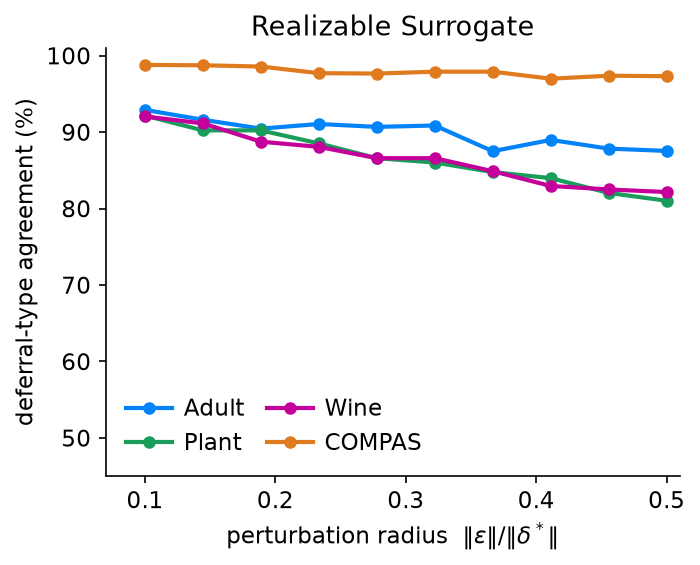

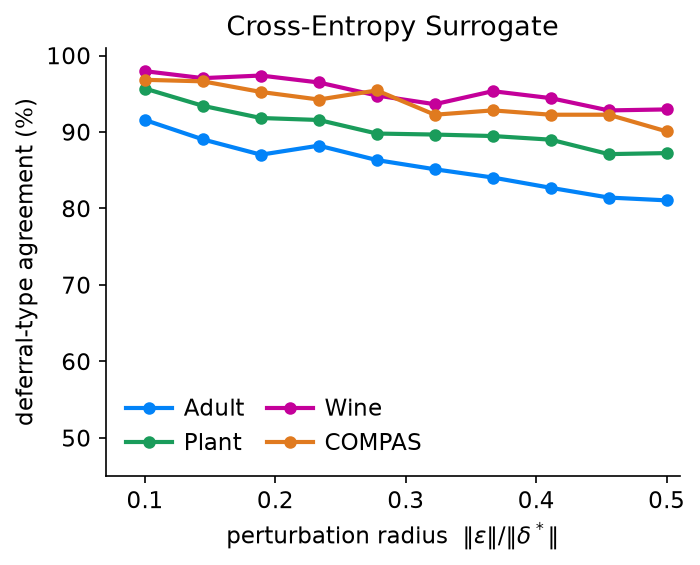

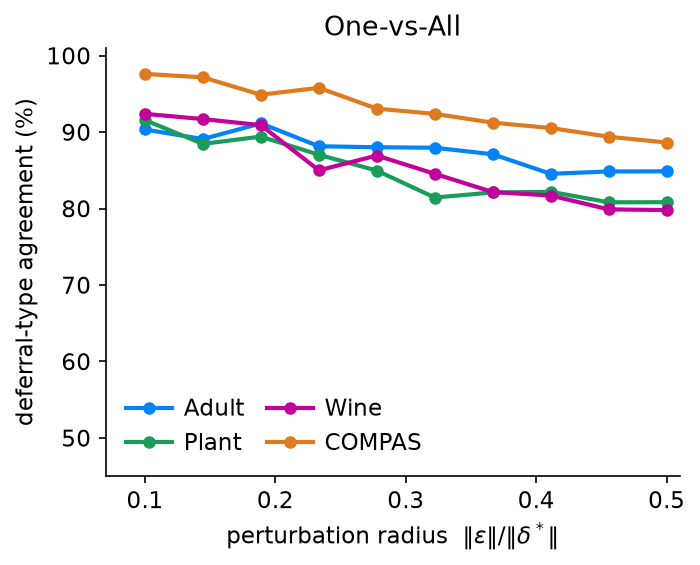

In [5]:
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"adult": "#0283F8", "plant": "#1A9C5B", "wine": "#C4009A", "compas": "#E07A1F"}
for m in core.METHODS:
    fig, ax = plt.subplots(figsize=(4.8, 3.9), dpi=150)
    for d, color in COLORS.items():
        curve = curves.loc[(m, d)]
        ax.plot(curve.index, curve.values, "o-", color=color, lw=2, ms=5, label=core.DATASET_LABELS[d])
    ax.set(xlim=(0.07, 0.51), ylim=(45, 101), title=core.METHOD_LABELS[m], ylabel="deferral-type agreement (%)",
           xlabel=r"perturbation radius  $\|\epsilon\|/\|\delta^*\|$")
    ax.legend(frameon=False, loc="lower left", ncol=2, columnspacing=1.0, handletextpad=0.5)
    fig.tight_layout()
    fig.savefig(OUT / f"robustness_typeagreement_{m}_all_datasets.pdf", bbox_inches="tight")
    plt.show()